In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

from pathlib import Path
import pandas as pd
from IPython import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
WORKERS = 8


In [2]:
"""Shared open-set helpers: person key order and the empirical CCR-FPIR curve."""

import re

import numpy as np
import pandas as pd


CORE_MATERIALS = ['plastic', 'glass', 'metal', 'ceramic', 'wood']


def person_key(person):
    match = re.fullmatch(r'H(\d+)', str(person))
    return (0, int(match.group(1))) if match else (1, str(person))


def ccr_fpir_curve(present, absent):
    """One shared threshold, both denominators include all their searches."""
    if present.empty or absent.empty:
        raise ValueError('Both present and absent cohorts must be nonempty.')
    thresholds = np.r_[np.inf, np.unique(np.r_[present.score, absent.score])[::-1]]
    if thresholds[-1] != 0:
        thresholds = np.r_[thresholds, 0.0]
    correct_scores = np.sort(present.loc[present.top_is_true.eq(1), 'score'].to_numpy())
    absent_scores = np.sort(absent.score.to_numpy())
    return pd.DataFrame({
        'tau': thresholds,
        'FPIR': (len(absent_scores) - np.searchsorted(absent_scores, thresholds, side='left')) / len(absent),
        'CCR': (len(correct_scores) - np.searchsorted(correct_scores, thresholds, side='left')) / len(present)})


In [3]:
"""Paired 10-person open-set engine (scheme B); workers cache probabilities
and exact preprocessing provenance, not the 2,080 fitted forests."""

from concurrent.futures import ProcessPoolExecutor, as_completed
import json
import multiprocessing
import os
from pathlib import Path
import time

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import normalize


PAIR_VERSION = 'paired-ab-v1'
PAIR_RF_PARAMS = dict(n_estimators=500, oob_score=True, random_state=11, n_jobs=1)
_DATA = None


class EnrollmentData:
    def __init__(self, raw):
        self.matrix = raw.data.tocsr()
        self.metadata = raw.sample_metadata.copy()
        self.feature_ids = raw.feature_metadata.index.tolist()
        self.sample_ids = self.metadata.index.tolist()
        self.sample_position = {s: i for i, s in enumerate(self.sample_ids)}
        # Sample filters (skin palms, >=3 samples per identity, reads >500) are
        # applied before any data-dependent feature screening.
        pool_md = raw.sample_metadata
        palms = raw.filter_ids(pool_md.index[
            pool_md.sample_type.eq('skin') & pool_md.surface_type.isin(['Rpalm', 'Lpalm'])], axis=0)
        pool = (palms.filter_sample_categories('individual', min_samples=3)
                .filter_sample_categories('individual', min_samples=3)
                .filter_by_metadata('_calour_original_abundance', select=lambda x: x > 500))
        self.people = sorted(pool.sample_metadata.individual.unique(), key=person_key)
        # Material queries are selected by metadata and read depth only; actual
        # two-person touches are excluded.
        material = self.metadata.surface_type.isin(CORE_MATERIALS)
        kinds = self.metadata.sample_type.isin(['surface_touched', 'surface_ctrl'])
        depth = self.metadata._calour_original_abundance > 200
        double = (self.metadata.individual.str.startswith('pair_', na=False) |
                  (self.metadata.pair1_resident.notna() & self.metadata.pair2_perp.notna()))
        self.queries = self.metadata.loc[material & kinds & depth & ~double].copy()
        self.queries = self.queries.sort_values('_calour_original_abundance', kind='mergesort')
        self.targets = sorted(self.queries.loc[self.queries.sample_type.eq('surface_touched'),
                                               'individual'].unique(), key=person_key)
        assert set(self.targets) <= set(self.people)
        self.train_positions = {
            p: np.array([self.sample_position[s] for s in pool.sample_metadata.index[
                pool.sample_metadata.individual.eq(p)]], dtype=int) for p in self.people}
        self.screen_positions = {
            p: np.flatnonzero(self.metadata.sample_type.eq('skin') & self.metadata.individual.eq(p))
            for p in self.people}
        # Per-person sums can be reused: each row is normalized independently.
        # No held-out data enters a selected training group's sum.
        self.screen_sums = {
            p: np.asarray(normalize(self.matrix[idx], norm='l1', axis=1).sum(axis=0)).ravel() * 100
            for p, idx in self.screen_positions.items()}
        self.signature = joblib.hash((PAIR_VERSION, self.matrix, self.metadata,
                                       self.feature_ids, PAIR_RF_PARAMS))

    def prepare(self, people, query_ids):
        people = sorted(people, key=person_key)
        assert len(people) == len(set(people)) and set(people) <= set(self.people)
        screen_sum = np.sum([self.screen_sums[p] for p in people], axis=0)
        screened = np.flatnonzero(screen_sum >= 0.01)
        train_idx = np.sort(np.concatenate([self.train_positions[p] for p in people]))
        screen_idx = np.sort(np.concatenate([self.screen_positions[p] for p in people]))
        tx = normalize(self.matrix[train_idx][:, screened], norm='l1', axis=1) * 100
        nonzero = np.asarray(tx.sum(axis=0)).ravel() > 0
        features = screened[nonzero]
        tx = tx[:, nonzero].tocsr()
        query_idx = np.array([self.sample_position[q] for q in query_ids])
        qx = normalize(self.matrix[query_idx][:, screened], norm='l1', axis=1) * 100
        qx = qx[:, nonzero].tocsr()
        labels = self.metadata.iloc[train_idx].individual.to_numpy()
        assert set(labels) == set(people)
        assert not set(train_idx) & set(query_idx)
        provenance = dict(train_positions=train_idx, screen_positions=screen_idx,
                          screened_features=screened, training_features=features)
        return tx, labels, qx, provenance

    def target_queries(self, target):
        qm = self.queries
        touched = qm.index[qm.sample_type.eq('surface_touched') & qm.individual.eq(target)].tolist()
        # Controls do not have a true toucher. Named residents are excluded via
        # the target's absent model; anonymous controls are tested in every target scenario.
        controls = qm.index[qm.sample_type.eq('surface_ctrl') &
                            (qm.individual.eq(target) | qm.individual.eq('surface'))].tolist()
        return touched, controls


def fit_predict(data, people, query_ids, cache_path):
    cache_path = Path(cache_path)
    signature = joblib.hash((data.signature, sorted(people, key=person_key), query_ids, PAIR_RF_PARAMS))
    if cache_path.exists():
        result = joblib.load(cache_path)
        assert result['signature'] == signature, f'Stale cache: {cache_path}'
        return result
    started = time.perf_counter()
    tx, y, qx, provenance = data.prepare(people, query_ids)
    model = RandomForestClassifier(**PAIR_RF_PARAMS)
    model.fit(tx, y)
    p = pd.DataFrame(model.predict_proba(qx), index=query_ids, columns=model.classes_)
    assert np.allclose(p.sum(axis=1), 1)
    result = dict(signature=signature, people=sorted(people, key=person_key),
                  P=p, provenance=provenance, rf_params=PAIR_RF_PARAMS,
                  train_samples=len(y), features=tx.shape[1],
                  oob_accuracy=float(model.oob_score_),
                  fit_predict_seconds=time.perf_counter() - started)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    temporary = cache_path.with_name(cache_path.name + f'.tmp-{os.getpid()}')
    joblib.dump(result, temporary, compress=3)
    temporary.replace(cache_path)
    return result


def _worker_init(data):
    global _DATA
    _DATA = data


def _run_task(task):
    target, rep, plus, minus, output = task
    touched, controls = _DATA.target_queries(target)
    folder = Path(output) / target
    fit_predict(_DATA, plus, touched, folder / f'rep-{rep:02d}-present.joblib')
    fit_predict(_DATA, minus, touched + controls, folder / f'rep-{rep:02d}-absent.joblib')
    return target, rep


def _search_rows(probability, query_ids, members, target, rep, list_type,
                 model_id, metadata, role='touched_id'):
    slice_p = probability.loc[query_ids, members]
    scores = slice_p.to_numpy()
    chosen = np.asarray(members)[scores.argmax(axis=1)]
    md = metadata.loc[query_ids]
    return pd.DataFrame(dict(
        sample=query_ids, target=target, true_or_claimed=target,
        rep=rep, role=role, list_type=list_type, model_id=model_id,
        list_members='|'.join(sorted(members)), list_order='|'.join(members),
        top_id=chosen, score=scores.max(axis=1),
        top_is_true=(chosen == target).astype(float) if list_type == 'present' else np.nan,
        query_identity=md.individual.to_numpy(), surface_type=md.surface_type.to_numpy(),
        year=md.year.to_numpy(), experiment=md.experiment.to_numpy(),
        n_reads=md._calour_original_abundance.to_numpy()))


In [4]:
import calour as ca

ca.set_log_level('ERROR')
raw = ca.read_amplicon(
    str(ROOT / 'data/reference-hit.2026.biom'), str(ROOT / 'data/merged_mapping.txt'),
    normalize=None, min_reads=0,
    sample_metadata_kwargs=dict(na_values=['unknown'], dtype={'persistence_time_sec': str}))

# 52 targets x 20 draws: nine shared people D plus one replacement z per repetition.
data = EnrollmentData(raw)
rng = np.random.default_rng(20261108)
draw_rows = []
for target in sorted(data.targets, key=person_key):
    others = np.array([p for p in sorted(data.people, key=person_key) if p != target])
    for rep in range(20):
        chosen = rng.choice(others, 10, replace=False).tolist()
        distractors, z = chosen[:-1], chosen[-1]
        draw_rows.append(dict(target=target, rep=rep, distractors='|'.join(distractors),
                              replacement=z, present_list='|'.join(distractors + [target]),
                              absent_list='|'.join(distractors + [z]), K=10, R=20,
                              candidate_seed=20261108))
draws = pd.DataFrame(draw_rows)
draws.to_csv(RESULTS_DIR / 'candidate-draws.csv', index=False)
config = dict(version=PAIR_VERSION, data_signature=data.signature, R=20, K=10,
              candidate_seed=20261108, RF_PARAMS=PAIR_RF_PARAMS)
config_path = RESULTS_DIR / 'configuration.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, 'Configuration changed; use another output directory.'
config_path.write_text(json.dumps(config, indent=2) + '\n')

# The benchmark pair is the first real pair; it becomes part of the final run.
first = next(draws.itertuples(index=False))
_worker_init(data)
start = time.perf_counter()
_run_task((first.target, first.rep, first.present_list.split('|'),
           first.absent_list.split('|'), str(RESULTS_DIR / 'cache')))
print(f'Pair benchmark fit: {time.perf_counter() - start:.2f}s wall time; '
      f'{len(data.targets) * 20} pairs total.', flush=True)
tasks = [(d.target, d.rep, d.present_list.split('|'), d.absent_list.split('|'),
          str(RESULTS_DIR / 'cache')) for d in draws.itertuples(index=False)]
started, completed = time.perf_counter(), 0
with ProcessPoolExecutor(max_workers=WORKERS, mp_context=multiprocessing.get_context('fork'),
                         initializer=_worker_init, initargs=(data,)) as executor:
    futures = [executor.submit(_run_task, task) for task in tasks]
    for future in as_completed(futures):
        future.result()
        completed += 1
        if completed % 100 == 0 or completed == len(tasks):
            print(f'{completed}/{len(tasks)} tasks; elapsed {time.perf_counter()-started:.1f}s', flush=True)

# Collect the probability caches into per-search rows.
rows = []
for draw in draws.itertuples(index=False):
    target, rep = draw.target, draw.rep
    touched, _ = data.target_queries(target)
    plus, minus = draw.present_list.split('|'), draw.absent_list.split('|')
    present_model, absent_model = f'{target}-r{rep:02d}-present', f'{target}-r{rep:02d}-absent'
    present_result = joblib.load(RESULTS_DIR / 'cache' / target / f'rep-{rep:02d}-present.joblib')
    absent_result = joblib.load(RESULTS_DIR / 'cache' / target / f'rep-{rep:02d}-absent.joblib')
    assert target in present_result['people'] and target not in absent_result['people']
    rows.append(_search_rows(present_result['P'], touched, plus, target, rep, 'present',
                             present_model, data.queries))
    rows.append(_search_rows(absent_result['P'], touched, minus, target, rep, 'absent',
                             absent_model, data.queries))
searches = pd.concat(rows, ignore_index=True)
assert not searches.duplicated(['sample', 'rep', 'list_type']).any()
searches.to_pickle(RESULTS_DIR / 'searches.pkl.bz2')

pres = searches[searches.list_type.eq('present')]
abse = searches[searches.list_type.eq('absent')]
curve = ccr_fpir_curve(pres, abse)
curve.to_csv(RESULTS_DIR / 'ccr-fpir-curve.csv', index=False)

# Rates at example thresholds: the least strict observed cutoff with tau >= value,
# so accepting scores >= tau is reproduced exactly on the observed score grid.
threshold_rows = []
for threshold in [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]:
    row = curve[curve.tau >= threshold].iloc[-1]
    threshold_rows.append(dict(protocol='paired',
                               description='Candidate-only top-1: 10 paired classes',
                               tau=threshold, CCR=float(row.CCR), FPIR=float(row.FPIR)))
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(RESULTS_DIR / 'rates-at-example-thresholds.csv', index=False)

# One paired, threshold-free row per target/sample/repetition.
keys = ['target', 'sample', 'rep']
metadata = ['surface_type', 'year', 'experiment', 'n_reads']
outcome = ['top_id', 'score', 'list_order', 'model_id']
labels = dict(top_id='top_id', score='top_probability', list_order='candidates', model_id='model')
present = pres.loc[:, keys + metadata + outcome + ['top_is_true']].copy()
absent = abse.loc[:, keys + outcome].copy()
present.rename(columns={**{k: f'present_{v}' for k, v in labels.items()},
                        'top_is_true': 'present_top_is_true'}, inplace=True)
absent.rename(columns={k: f'absent_{v}' for k, v in labels.items()}, inplace=True)
table = present.merge(absent, on=keys, validate='one_to_one')
assert len(table) == len(present) == len(absent)
table = table.merge(draws[['target', 'rep', 'replacement', 'candidate_seed']],
                    on=['target', 'rep'], how='left', validate='many_to_one')
assert table.candidate_seed.notna().all()
table['repetition'] = table.rep + 1
table['present_top_is_true'] = table.present_top_is_true.astype(int)
order = {p: i for i, p in enumerate(sorted(table.target.unique(), key=person_key))}
table['_person_order'] = table.target.map(order)
table.sort_values(['_person_order', 'sample', 'rep'], inplace=True)
columns = ['target', 'sample', 'repetition',
           'present_top_id', 'present_top_probability', 'present_top_is_true',
           'absent_top_id', 'absent_top_probability',
           *metadata, 'present_candidates', 'absent_candidates',
           'present_model', 'absent_model', 'replacement', 'candidate_seed']
table[columns].to_csv(RESULTS_DIR / 'top1-results.csv', index=False, encoding='utf-8-sig')

summary = dict(query_people=len(data.targets),
               touched_queries=pres['sample'].nunique(), present_searches=len(pres),
               absent_searches=len(abse), top1_accuracy=float(pres.top_is_true.mean()),
               K=10, R=20, training_classes='10 present / 10 absent',
               score='raw maximum probability among 10 candidates; no slice renormalization',
               threshold_selection='none; descriptive curves only',
               uncertainty='conditional on saved fitted models and sampled training/candidate groups')
(RESULTS_DIR / 'run-summary.json').write_text(json.dumps(summary, indent=2) + '\n')
print(json.dumps(summary, indent=2), flush=True)
display.display(pd.DataFrame([summary])[[
    'training_classes', 'touched_queries',
    'present_searches', 'absent_searches', 'top1_accuracy']])


/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_repeats=1, random_state=None as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "
/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_splits=3, n_repeats=1 as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "


Pair benchmark fit: 0.01s wall time; 1040 pairs total.
100/1040 tasks; elapsed 0.4s
200/1040 tasks; elapsed 0.5s
300/1040 tasks; elapsed 0.5s
400/1040 tasks; elapsed 0.6s
500/1040 tasks; elapsed 0.7s
600/1040 tasks; elapsed 0.8s
700/1040 tasks; elapsed 0.9s
800/1040 tasks; elapsed 0.9s
900/1040 tasks; elapsed 1.0s
1000/1040 tasks; elapsed 1.1s
1040/1040 tasks; elapsed 1.1s
{
  "query_people": 52,
  "touched_queries": 754,
  "present_searches": 15080,
  "absent_searches": 15080,
  "top1_accuracy": 0.5651193633952255,
  "K": 10,
  "R": 20,
  "training_classes": "10 present / 10 absent",
  "score": "raw maximum probability among 10 candidates; no slice renormalization",
  "threshold_selection": "none; descriptive curves only",
  "uncertainty": "conditional on saved fitted models and sampled training/candidate groups"
}


,training_classes,touched_queries,present_searches,absent_searches,top1_accuracy
0,10 present / 10 absent,754,15080,15080,0.565119


In [5]:
"""Scheme B predictive Shannon entropy: per-search bits from the saved
probability caches, then person/material means, paired tests and the figure."""

import joblib
import numpy as np
import pandas as pd
from scipy.special import xlogy
from scipy.stats import binomtest, wilcoxon


searches = pd.read_pickle(RESULTS_DIR / 'searches.pkl.bz2')
frames = []
for (_, target, rep, side), group in searches.groupby(
        ['model_id', 'target', 'rep', 'list_type'], sort=False):
    cached = joblib.load(RESULTS_DIR / 'cache' / target / f'rep-{rep:02d}-{side}.joblib')
    candidates = group.list_order.iloc[0].split('|')
    assert len(candidates) == 10 and set(candidates) == set(cached['P'].columns)
    assert group.list_order.nunique() == 1
    p = cached['P'].loc[group['sample'], candidates].to_numpy()
    assert np.isfinite(p).all() and (p >= 0).all()
    np.testing.assert_allclose(p.sum(axis=1), 1, rtol=0, atol=1e-12)
    np.testing.assert_allclose(p.max(axis=1), group.score, rtol=0, atol=1e-12)
    np.testing.assert_array_equal(np.asarray(candidates)[p.argmax(axis=1)], group.top_id)
    bits = -xlogy(p, p).sum(axis=1) / np.log(2)
    frame = group[['target', 'sample', 'rep', 'list_type']].copy()
    frame['shannon_bits'] = bits
    frame['entropy_normalized'] = bits / np.log2(len(candidates))
    frames.append(frame)
entropy = pd.concat(frames, ignore_index=True)
assert entropy.entropy_normalized.between(-1e-12, 1 + 1e-12).all()

paired = pd.read_csv(RESULTS_DIR / 'top1-results.csv')
original_rows = len(paired)
for side in ['present', 'absent']:
    frame = entropy[entropy.list_type.eq(side)].copy()
    frame['repetition'] = frame.rep + 1
    frame.rename(columns={c: f'{side}_{c}' for c in ['shannon_bits', 'entropy_normalized']}, inplace=True)
    paired = paired.merge(frame[['target', 'sample', 'repetition',
                                 f'{side}_shannon_bits', f'{side}_entropy_normalized']],
                          on=['target', 'sample', 'repetition'], validate='one_to_one')
entropy_columns = [f'{side}_{metric}' for side in ['present', 'absent']
                   for metric in ['shannon_bits', 'entropy_normalized']]
assert len(paired) == original_rows and paired[entropy_columns].notna().all().all()

# Per-search entropy -> sample means -> person/material means -> paired Holm tests.
metrics = ['present_shannon_bits', 'absent_shannon_bits']
sample = paired.groupby(['target', 'surface_type', 'sample'], sort=False)[metrics].mean()
frame = sample.groupby(['target', 'surface_type'], sort=False)[metrics].mean()
frame['material_samples'] = sample.groupby(['target', 'surface_type'], sort=False).size()
frame['entropy_difference_absent_minus_present'] = frame.absent_shannon_bits - frame.present_shannon_bits
frame.to_csv(RESULTS_DIR / 'entropy-person-material.csv', encoding='utf-8-sig')
frame = frame.reset_index()
materials = ['plastic', 'glass', 'ceramic', 'metal', 'wood']
assert set(frame.surface_type) == set(materials)
rows = []
for material in materials:
    people = frame[frame.surface_type.eq(material)]
    d = np.round(people.entropy_difference_absent_minus_present.to_numpy(), 12)
    if (d != 0).any():
        result = wilcoxon(d, zero_method='wilcox', alternative='two-sided', correction=True, method='approx')
        statistic, p_value = float(result.statistic), float(result.pvalue)
        sign_p = binomtest(int((d > 0).sum()), int((d != 0).sum()), alternative='two-sided').pvalue
    else:
        statistic, p_value, sign_p = 0.0, 1.0, 1.0
    rows.append(dict(surface_type=material, n_people=len(people),
                     material_samples=int(people.material_samples.sum()),
                     present_mean=people.present_shannon_bits.mean(),
                     absent_mean=people.absent_shannon_bits.mean(),
                     mean_difference=people.entropy_difference_absent_minus_present.mean(),
                     positive_differences=int((d > 0).sum()),
                     negative_differences=int((d < 0).sum()),
                     wilcoxon_W=statistic, wilcoxon_p=p_value, sign_test_p=sign_p))
statistics = pd.DataFrame(rows)
for column in ['wilcoxon_p', 'sign_test_p']:
    order = np.argsort(statistics[column].to_numpy())
    adjusted = np.minimum(1, np.maximum.accumulate(
        statistics[column].to_numpy()[order] * np.arange(len(order), 0, -1)))
    statistics[column + '_holm'] = np.nan
    statistics.loc[order, column + '_holm'] = adjusted
statistics['test'] = 'two-sided paired Wilcoxon, normal approximation, continuity correction'
statistics['correction'] = 'Holm across five materials; sign tests adjusted as a separate sensitivity family'
statistics['scope'] = 'person means conditional on saved fits and draws; material cohorts differ'
statistics.to_csv(RESULTS_DIR / 'entropy-by-material-paired-tests.csv', index=False)

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

colors = ['#2678b2', '#d25b36']
fig, ax = plt.subplots(figsize=(5.8, 3.3))
rng = np.random.default_rng(20261109)
bracket_tops = []
for i, material in enumerate(materials):
    group = frame[frame.surface_type.eq(material)]
    values = group[['present_shannon_bits', 'absent_shannon_bits']].to_numpy()
    positions = i + np.array([-0.18, 0.18])
    boxes = ax.boxplot(values, positions=positions, widths=0.26, patch_artist=True,
                       showfliers=False,
                       boxprops={'edgecolor': '#333333', 'linewidth': 1.05},
                       medianprops={'color': '#222222', 'linewidth': 1.5},
                       whiskerprops={'color': '#333333', 'linewidth': 0.9},
                       capprops={'color': '#333333', 'linewidth': 0.9})
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)
    jitter = rng.uniform(-0.065, 0.065, len(values))
    for offset, row in zip(jitter, values):
        ax.plot(positions + offset, row, color='#999999', alpha=0.23, lw=0.5, zorder=1)
    for j, color in enumerate(colors):
        ax.scatter(positions[j] + jitter, values[:, j], s=12, color=color,
                   edgecolor='#333333', linewidth=0.55, alpha=0.42, zorder=3)
    bracket_y = values.max() + 0.06
    bracket_tops.append(bracket_y + 0.18)
    ax.plot([positions[0], positions[0], positions[1], positions[1]],
            [bracket_y, bracket_y + 0.025, bracket_y + 0.025, bracket_y], color='#222222', lw=0.85)
    p_value = statistics.loc[statistics.surface_type.eq(material), 'wilcoxon_p_holm'].iloc[0]
    if p_value >= 0.001:
        label = f'{p_value:.3f}'
    else:
        exponent = int(np.floor(np.log10(p_value)))
        label = rf'{p_value / 10 ** exponent:.1f}\times10^{{{exponent}}}'
    ax.text(i, bracket_y + 0.045, rf'$P_{{adj}}={label}$', ha='center', va='bottom', fontsize=7.2)
ax.axhline(np.log2(10), color='#777777', ls='--', lw=0.85)
lower = np.floor((frame[['present_shannon_bits', 'absent_shannon_bits']].to_numpy().min() - 0.08) * 10) / 10
ax.set(xlim=(-0.55, len(materials) - 0.45), ylim=(lower, max(np.log2(10) + 0.08, max(bracket_tops))),
       xticks=np.arange(len(materials)),
       xticklabels=[f'{row.surface_type}\n(n={row.n_people})' for row in statistics.itertuples()],
       ylabel='Mean Shannon entropy')
ax.yaxis.label.set_size(9)
ax.tick_params(labelsize=8.5, width=1, length=3)
for spine in ax.spines.values():
    spine.set(color='#777777', linewidth=1.05)
ax.legend(handles=[Patch(facecolor=color, edgecolor='#333333', label=label)
                   for color, label in zip(colors, ['Target present', 'Target absent'])],
          loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False,
          fontsize=9, handlelength=1.2, borderaxespad=0)
fig.tight_layout(pad=0.6)
for ext in ['png', 'pdf']:
    fig.savefig(RESULTS_DIR / f'shannon-entropy-by-material.{ext}', dpi=200, bbox_inches='tight')
plt.close(fig)


In [6]:
"""Top-1/2/3 lists under the shared maximum-probability acceptance rule:
ranks from the saved caches, curves, operating points and the published figure."""

import joblib
import numpy as np
import pandas as pd


TOPK_MATERIALS = ['plastic', 'glass', 'ceramic', 'metal', 'wood']
COLORS = {1: '#2678b2', 2: '#d56a29', 3: '#27865c'}
CAPS = [0.01, 0.05, 0.10]
EXAMPLE_TAUS = [0.7, 0.5, 0.4, 0.3, 0.2, 0.1]

# Descending ranks preserving the saved candidate order for ties; no refitting,
# no probability averaging.
paired = pd.read_csv(RESULTS_DIR / 'top1-results.csv', float_precision='round_trip')
for (target, repetition), group in paired.groupby(['target', 'repetition'], sort=False):
    for side in ['present', 'absent']:
        assert group[f'{side}_candidates'].nunique() == 1
        candidates = group[f'{side}_candidates'].iloc[0].split('|')
        cached = joblib.load(RESULTS_DIR / 'cache' / target /
                             f'rep-{repetition - 1:02d}-{side}.joblib')
        probabilities = cached['P'].loc[group['sample'], candidates]
        assert set(candidates) == set(cached['P'].columns)
        assert (target in candidates) == (side == 'present')
        values = probabilities.loc[:, candidates].to_numpy()
        assert len(candidates) == len(set(candidates)) == 10
        assert np.isfinite(values).all() and (values >= 0).all() and (values <= 1).all()
        np.testing.assert_allclose(values.sum(axis=1), 1, rtol=0, atol=1e-12)
        order = np.argsort(-values, axis=1, kind='stable')
        ids = np.asarray(candidates)[order]
        scores = np.take_along_axis(values, order, axis=1)
        rank = (ids == target).argmax(axis=1) + 1 if target in candidates else None
        np.testing.assert_array_equal(ids[:, 0], group[f'{side}_top_id'])
        np.testing.assert_allclose(scores[:, 0], group[f'{side}_top_probability'],
                                   rtol=0, atol=1e-15)
        for k in [2, 3]:
            paired.loc[group.index, f'{side}_rank{k}_id'] = ids[:, k - 1]
            paired.loc[group.index, f'{side}_rank{k}_probability'] = scores[:, k - 1]
        if side == 'present':
            paired.loc[group.index, 'present_true_rank'] = rank
            true_score = probabilities[target].to_numpy()
            paired.loc[group.index, 'present_true_probability'] = true_score
            paired.loc[group.index, 'present_true_score_tie_size'] = (
                probabilities.to_numpy() == true_score[:, None]).sum(axis=1)
for column in ['present_true_rank', 'present_true_score_tie_size']:
    paired[column] = paired[column].astype(int)
for k in [1, 2, 3]:
    paired[f'present_hit_top{k}'] = paired.present_true_rank.le(k).astype(int)
np.testing.assert_array_equal(paired.present_hit_top1, paired.present_top_is_true)

# p_max >= tau accepts a whole list; the true identity inside the first k counts
# as a correct identification. FPIR uses the absent side of the same rule.
curves, point_rows = [], []
groups = [('overall', paired)] + [(material, paired.loc[paired.surface_type.eq(material)])
                                  for material in TOPK_MATERIALS]
for scope, group in groups:
    common = None
    for k in [1, 2, 3]:
        present = pd.DataFrame(dict(score=group.present_top_probability,
                                    top_is_true=group[f'present_hit_top{k}']))
        absent = pd.DataFrame(dict(score=group.absent_top_probability))
        curve = ccr_fpir_curve(present, absent)
        curve['scope'] = scope
        curve['top_k'] = k
        # Analytical expectation for uniform random lists and an independent,
        # shared acceptance probability q: FPIR = q, CCR = q * k / 10.
        curve['random_CCR'] = curve.FPIR * k / 10
        curve['n_people'] = group.target.nunique()
        curve['n_samples'] = group['sample'].nunique()
        curve['searches_per_side'] = len(group)
        curves.append(curve)
        if common is None:
            # The least restrictive observed cutoff satisfying each cap is common
            # to all ranks and maximizes every monotone rank curve.
            common = [(cap, curve.loc[curve.FPIR.le(cap)].iloc[-1].tau) for cap in CAPS]
        for cap, tau in common:
            row = curve.loc[curve.tau.eq(tau)].iloc[0]
            point_rows.append(dict(scope=scope, top_k=k, fpir_cap=cap, threshold=tau,
                                   FPIR=row.FPIR, CCR=row.CCR, random_CCR=row.random_CCR,
                                   acceptance_rule='maximum probability >= threshold',
                                   success_rule=f'true identity in first {k} candidates',
                                   selection='lowest observed cutoff satisfying FPIR cap; shared across ranks'))
curves = pd.concat(curves, ignore_index=True)
points = pd.DataFrame(point_rows)
# The overall Top-1 curve must reproduce the engine's curve exactly.
original = pd.read_csv(RESULTS_DIR / 'ccr-fpir-curve.csv', float_precision='round_trip')
reproduced = curves.loc[curves.scope.eq('overall') & curves.top_k.eq(1), ['tau', 'FPIR', 'CCR']]
np.testing.assert_allclose(reproduced, original, rtol=0, atol=1e-15)
curves.to_csv(RESULTS_DIR / 'topk-curves.csv', index=False)
points.to_csv(RESULTS_DIR / 'topk-operating-points.csv', index=False)

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

label_positions = [(.11, .055), (.17, .155), (.29, .245),
                   (.49, .345), (.76, .515), (.98, .575)]
align = ['left', 'left', 'left', 'left', 'right', 'right']
fig, axes = plt.subplots(1, 5, figsize=(13.2, 3.6), sharex=True, sharey=True)
for i, (material, ax) in enumerate(zip(TOPK_MATERIALS, axes)):
    selected = curves.loc[curves.scope.eq(material)]
    for k in [1, 2, 3]:
        topk_curve = selected.loc[selected.top_k.eq(k)]
        ax.step(topk_curve.FPIR, topk_curve.CCR, where='post', color=COLORS[k], lw=1.5,
                label=f'Top-{k}')
        ax.plot([0, 1], [0, k / 10], color=COLORS[k], lw=1, ls='--', alpha=0.8,
                label=f'Random Top-{k}')
        ax.set(xlim=(0, 1), ylim=(0, .95))
        ax.tick_params(labelsize=8.5)
    above = {.5: (.28, .62), .4: (.105, .43)} if material == 'wood' else {}
    adaptive_positions = []
    for tau_i, (tau, position) in enumerate(zip(EXAMPLE_TAUS, label_positions)):
        if tau not in [.2, .3, .4, .5]:
            continue
        decisions = []
        for k in [1, 2, 3]:
            curve_k = selected.loc[selected.top_k.eq(k)]
            row = curve_k.loc[curve_k.tau.ge(tau)].iloc[-1]
            decisions.append(row)
            ax.plot(row.FPIR, row.CCR, 'o', color=COLORS[k], markersize=3.4,
                    markeredgecolor='white', markeredgewidth=.45, clip_on=False, zorder=4)
        first, last = decisions[0], decisions[-1]
        ymin, ymax = ax.get_ylim()
        if tau in above:
            position = above[tau]
        else:
            offset = [.028, .045, -.055, -.095, -.115, -.065][tau_i]
            minimum_y = [.055, .105, .165, .23, .30, .37][tau_i]
            label_x = [.12, .24, .36, .53, .76, .98][tau_i]
            relative = max(minimum_y, (first.CCR - ymin) / (ymax - ymin) + offset)
            previous = adaptive_positions[-1] if adaptive_positions else -np.inf
            relative = max(relative, previous + .08)
            adaptive_positions.append(relative)
            position = (label_x, relative)
        ax.plot([first.FPIR, last.FPIR], [first.CCR, last.CCR],
                color='#555555', lw=1.3, ls=':', zorder=2)
        if tau in above:
            anchor = (last.FPIR, last.CCR)
            ha = 'center'
        else:
            anchor = (first.FPIR, first.CCR)
            ha = align[tau_i]
        ax.annotate(rf'$\tau={tau:g}$', anchor,
                    xytext=position, textcoords='axes fraction',
                    ha=ha, va='center', fontsize=7.2, color='#555555',
                    arrowprops=dict(arrowstyle='-', color='#777777', lw=.65),
                    bbox=dict(facecolor='white', edgecolor='none', alpha=.95, pad=1.2))
    for spine in ax.spines.values():
        spine.set(color='#777777', linewidth=1.05)
    row = selected.iloc[0]
    ax.set_title(f'{material.capitalize()}\n(n={int(row.n_people)})', fontsize=9.5)
    ax.set_xlabel('False positive identification rate (FPIR)', fontsize=9)
    ax.set_ylabel('Correct accepted identification rate', fontsize=9)
    ax.set_xlabel('')
    if i:
        ax.set_ylabel('')
fig.legend(handles=[Line2D([0], [0], color=COLORS[k], lw=2, label=f'Top-{k}')
                    for k in [1, 2, 3]]
           + [Line2D([0], [0], color='#555555', lw=1.5, label='Model'),
              Line2D([0], [0], color='#555555', lw=1.2, ls='--', label='Random')],
           loc='lower center', bbox_to_anchor=(.5, 1.0), ncol=5, frameon=False,
           fontsize=9, handlelength=1.4, handletextpad=.5, columnspacing=1.1,
           borderaxespad=0)
fig.supxlabel('False positive identification rate (FPIR)', fontsize=9)
fig.tight_layout(pad=1.1, w_pad=.8, rect=(0, .03, 1, .96))
for ext in ['png', 'pdf']:
    fig.savefig(RESULTS_DIR / f'topk-probability-ccr-fpir-full-by-material.{ext}',
                dpi=200, bbox_inches='tight')
plt.close(fig)
print('Saved Top-1/2/3 curves and the published per-material figure to results/.')


Saved Top-1/2/3 curves and the published per-material figure to results/.


In [ ]:
"""Per-material rates at fixed example thresholds: observed FPIR, correct
accepted Top-1/2/3 rates and the analytical random baseline (FPIR * k / 10)."""

rows = []
for material in TOPK_MATERIALS:
    group = paired.loc[paired.surface_type.eq(material)]
    for tau in [0.5, 0.4, 0.3, 0.2]:
        present_accept = group.present_top_probability.ge(tau)
        FPIR = group.absent_top_probability.ge(tau).mean()
        row = dict(surface_type=material, tau=tau,
                   n_people=group.target.nunique(), searches_per_side=len(group),
                   FPIR=FPIR)
        for k in [1, 2, 3]:
            row[f'CCR_top{k}'] = (present_accept
                                  & group[f'present_hit_top{k}']).mean()
        # Analytical expectation for uniform random lists and an independent,
        # shared acceptance probability q: FPIR = q, CCR = q * k / 10.
        for k in [1, 2, 3]:
            row[f'random_CCR_top{k}'] = FPIR * k / 10
        rows.append(row)
material_threshold_table = pd.DataFrame(rows)
material_threshold_table.to_csv(
    RESULTS_DIR / 'material-rates-at-example-thresholds.csv', index=False)
display.display(material_threshold_table.round(4))

In [7]:
"""Uncertainty U = 1 - maximum candidate probability: person/material means,
paired tests and the published per-material figure."""

import numpy as np
import pandas as pd
from scipy.stats import binomtest, wilcoxon


METRICS = ['present_uncertainty', 'absent_uncertainty',
           'uncertainty_difference_absent_minus_present']
UNC_MATERIALS = ['plastic', 'glass', 'ceramic', 'metal', 'wood']

paired = pd.read_csv(RESULTS_DIR / 'top1-results.csv', float_precision='round_trip')
assert not paired.duplicated(['target', 'sample', 'repetition']).any()
for side in ['present', 'absent']:
    score = paired[f'{side}_top_probability']
    # Ten candidate probabilities sum to one, so p_max >= 0.1 and U <= 0.9.
    assert score.between(.1 - 1e-12, 1).all()
    paired[f'{side}_uncertainty'] = 1 - score
paired[METRICS[2]] = paired.absent_uncertainty - paired.present_uncertainty
np.testing.assert_allclose(paired[METRICS[2]],
                           paired.present_top_probability - paired.absent_top_probability,
                           rtol=0, atol=2e-16)

# Average the 20 draws within a sample, then samples within each person/material;
# people keep equal weight. Twenty searches per sample are not twenty independent
# sample units, so SEMs are conditional sample SEMs and a single sample has no SEM.
sample = paired.groupby(['target', 'surface_type', 'sample'], sort=False)[METRICS].mean()
sample['draws'] = paired.groupby(['target', 'surface_type', 'sample'], sort=False).size()
assert sample.draws.eq(20).all()
groups = sample.groupby(['target', 'surface_type'], sort=False)
person_material = groups[METRICS].mean()
person_material = person_material.join(groups[METRICS].sem(ddof=1).add_suffix('_se'))
person_material['material_samples'] = groups.size()
person_material['paired_searches'] = groups.draws.sum()
person_material = person_material.reindex(pd.MultiIndex.from_tuples(
    sorted(person_material.index,
           key=lambda item: (person_key(item[0]), UNC_MATERIALS.index(item[1]))),
    names=person_material.index.names))
person_material.to_csv(RESULTS_DIR / 'uncertainty-person-material.csv')

# Person-level paired tests of U, with Holm adjustment over the five materials.
rows = []
for material in UNC_MATERIALS:
    group = person_material.xs(material, level='surface_type')
    difference = group[METRICS[2]].to_numpy()
    ranked = np.round(difference, 12)
    if (ranked != 0).any():
        result = wilcoxon(ranked, zero_method='wilcox', alternative='two-sided',
                          correction=True, method='approx')
        statistic, p_value = float(result.statistic), float(result.pvalue)
        sign_p = binomtest(int((ranked > 0).sum()), int((ranked != 0).sum()),
                           alternative='two-sided').pvalue
    else:
        statistic, p_value, sign_p = 0., 1., 1.
    rows.append(dict(
        surface_type=material, n_people=len(group),
        material_samples=int(group.material_samples.sum()),
        present_mean=group[METRICS[0]].mean(), absent_mean=group[METRICS[1]].mean(),
        mean_difference=difference.mean(),
        positive_differences=int((ranked > 0).sum()),
        negative_differences=int((ranked < 0).sum()),
        wilcoxon_W=statistic, wilcoxon_p=p_value, sign_test_p=sign_p))
statistics = pd.DataFrame(rows)
for column in ['wilcoxon_p', 'sign_test_p']:
    order = np.argsort(statistics[column].to_numpy())
    adjusted = np.minimum(1, np.maximum.accumulate(
        statistics[column].to_numpy()[order] * np.arange(len(order), 0, -1)))
    statistics[column + '_holm'] = np.nan
    statistics.loc[order, column + '_holm'] = adjusted
statistics['test'] = 'two-sided paired Wilcoxon; normal approximation; continuity correction; differences rounded to 12 decimals'
statistics['correction'] = 'Holm across five materials; sign tests adjusted as a separate sensitivity family'
statistics['scope'] = 'person means conditional on saved fits and draws; material cohorts differ'
statistics.to_csv(RESULTS_DIR / 'uncertainty-by-material-paired-tests.csv', index=False)

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

colors = ['#2678b2', '#d25b36']
rng = np.random.default_rng(20261109)
fig, ax = plt.subplots(figsize=(5.8, 3.3))
for i, material in enumerate(UNC_MATERIALS):
    group = person_material.xs(material, level='surface_type')
    values = group[METRICS[:2]].to_numpy()
    positions = i + np.array([-.18, .18])
    boxes = ax.boxplot(values, positions=positions, widths=.26,
                       patch_artist=True, showfliers=False,
                       boxprops=dict(edgecolor='#333333', linewidth=1.05),
                       medianprops=dict(color='#222222', linewidth=1.5),
                       whiskerprops=dict(color='#333333', linewidth=.9),
                       capprops=dict(color='#333333', linewidth=.9))
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color)
    jitter = rng.uniform(-.065, .065, len(group))
    for offset, pair in zip(jitter, values):
        ax.plot(positions + offset, pair, color='#999999', alpha=.23, lw=.5, zorder=1)
    for j, color in enumerate(colors):
        ax.scatter(positions[j] + jitter, values[:, j], s=12, color=color,
                   edgecolor='#333333', linewidth=.55, alpha=.42, zorder=3)
    bracket_y = values.max() + .025
    ax.plot([positions[0], positions[0], positions[1], positions[1]],
            [bracket_y, bracket_y + .012, bracket_y + .012, bracket_y],
            color='#222222', lw=.85)
    p_value = statistics.loc[statistics.surface_type.eq(material), 'wilcoxon_p_holm'].iloc[0]
    if p_value >= .001:
        label = f'{p_value:.3f}'
    else:
        exponent = int(np.floor(np.log10(p_value)))
        label = rf'{p_value / 10 ** exponent:.1f}\times10^{{{exponent}}}'
    ax.text(i, bracket_y + .022, rf'$P_{{adj}}={label}$',
            ha='center', va='bottom', fontsize=7.2)
ax.axhline(.9, color='#777777', ls='--', lw=.85)
lower = max(0., np.floor((person_material[METRICS[:2]].to_numpy().min() - .04) * 10) / 10)
ax.set(xlim=(-.55, len(UNC_MATERIALS) - .45), ylim=(lower, .95), xticks=np.arange(5),
       xticklabels=[f'{row.surface_type}\n(n={row.n_people})' for row in statistics.itertuples()],
       ylabel='Mean uncertainty')
ax.yaxis.label.set_size(9)
ax.tick_params(labelsize=8.5, width=1, length=3)
ax.legend(handles=[Patch(facecolor=color, edgecolor='#333333', label=label)
                   for color, label in zip(colors, ['Target present', 'Target absent'])],
          loc='lower center', bbox_to_anchor=(.5, 1.01), ncol=2,
          frameon=False, fontsize=9, handlelength=1.2, borderaxespad=0)
for spine in ax.spines.values():
    spine.set(color='#777777', linewidth=1.05)
fig.tight_layout(pad=.6)
for ext in ['png', 'pdf']:
    fig.savefig(RESULTS_DIR / f'uncertainty-by-material.{ext}',
                dpi=200, bbox_inches='tight')
plt.close(fig)


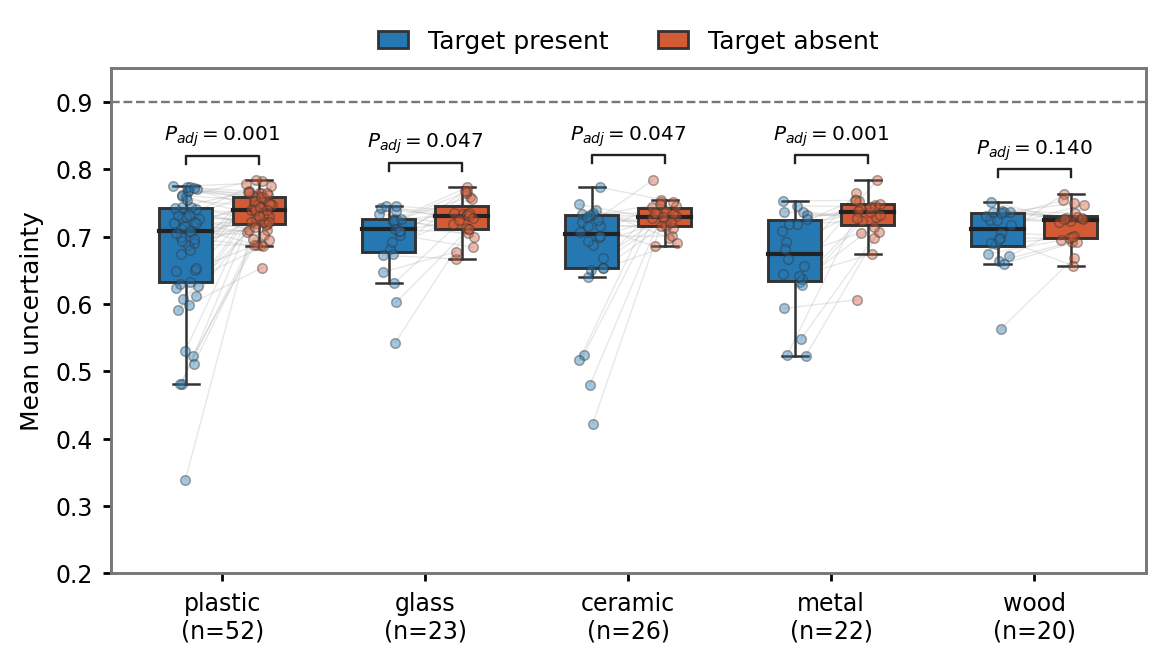

In [8]:
display.display(display.Image(filename=str(RESULTS_DIR / 'uncertainty-by-material.png')))

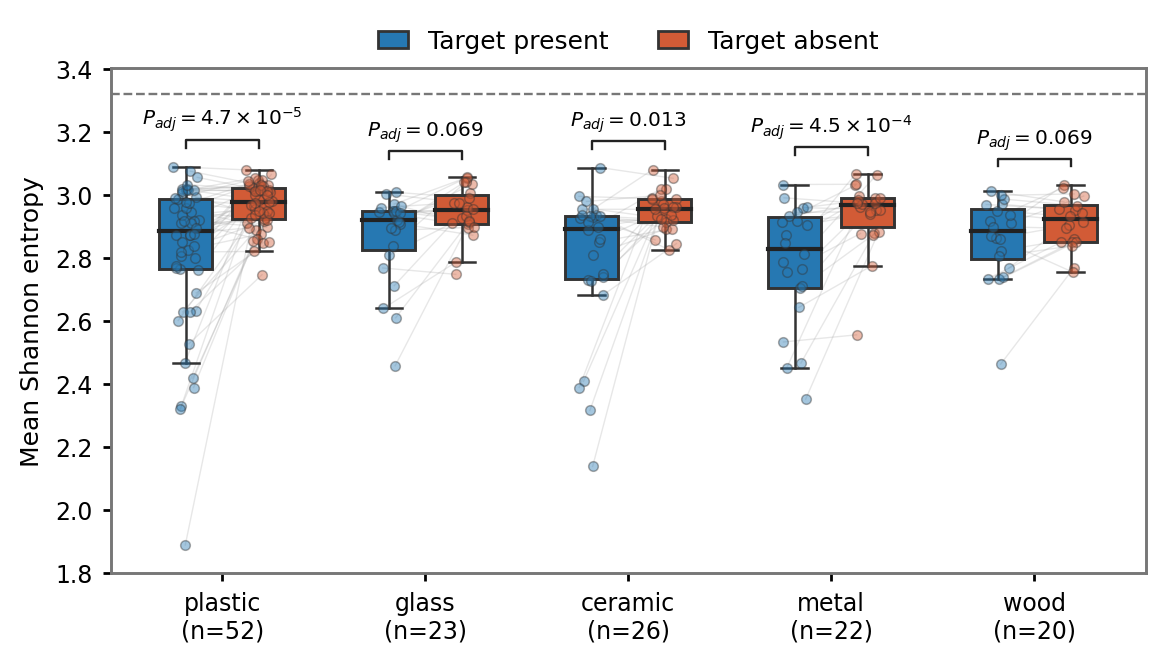

In [9]:
display.display(display.Image(filename=str(RESULTS_DIR / 'shannon-entropy-by-material.png')))

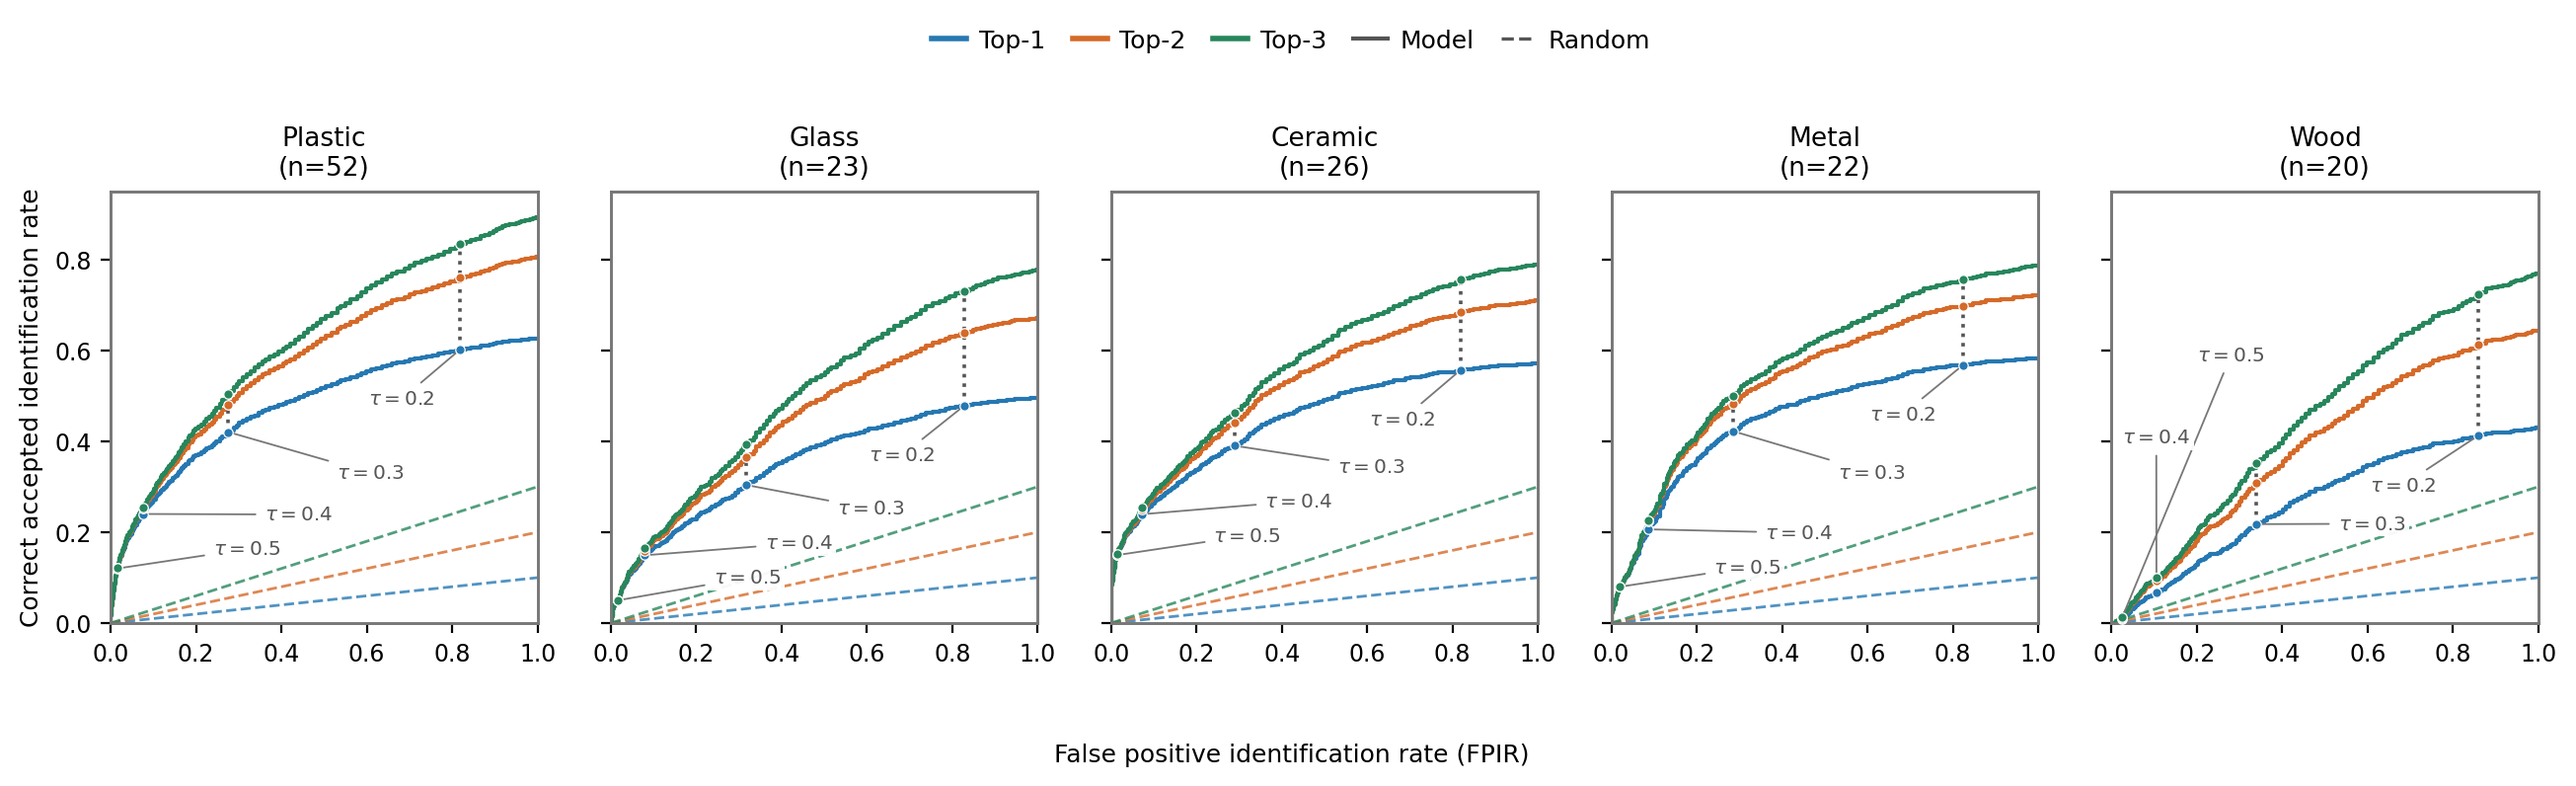

In [10]:
display.display(display.Image(filename=str(RESULTS_DIR / 'topk-probability-ccr-fpir-full-by-material.png')))